# Comprehensive Medical Cost Insurance Forecasting

This project uses Linear Regression to predict annual medical insurance charges based on demographic, health, family, and lifestyle-related features.

## Problem Statement

Health insurance providers need accurate estimates of expected medical costs to set appropriate premiums.

The objective of this project is to build a machine learning regression model that predicts an individual's annual medical insurance charges using features such as age, sex, BMI, number of children, smoking status, and region.

The target variable is `charges`.

Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Load Dataset

In [5]:
df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.shape

(1338, 7)

In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [8]:
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Categorical Data Analysis

In [11]:
print("Sex Distribution:")
print(df["sex"].value_counts())

print("\nSmoker Distribution:")
print(df["smoker"].value_counts())

print("\nRegion Distribution:")
print(df["region"].value_counts())

Sex Distribution:
sex
male      676
female    662
Name: count, dtype: int64

Smoker Distribution:
smoker
no     1064
yes     274
Name: count, dtype: int64

Region Distribution:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


Exploratory Data Analysis

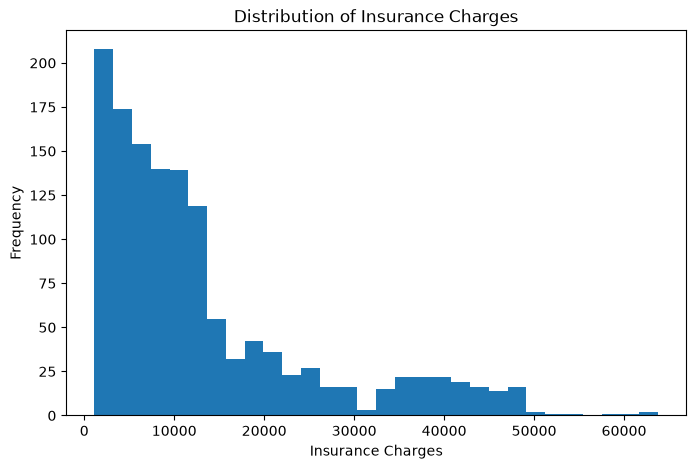

In [12]:
# Insurance Charges Distribution

plt.figure(figsize=(8, 5))

plt.hist(df["charges"], bins=30)

plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Insurance Charges")

plt.show()

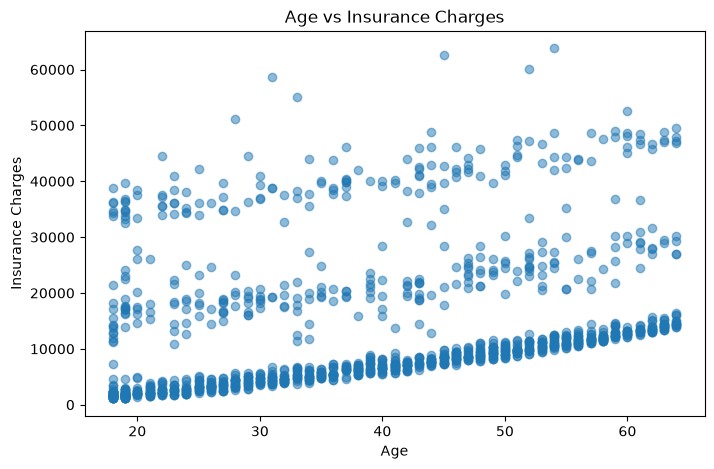

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df["age"], df["charges"], alpha=0.5)

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Age vs Insurance Charges")

plt.show()

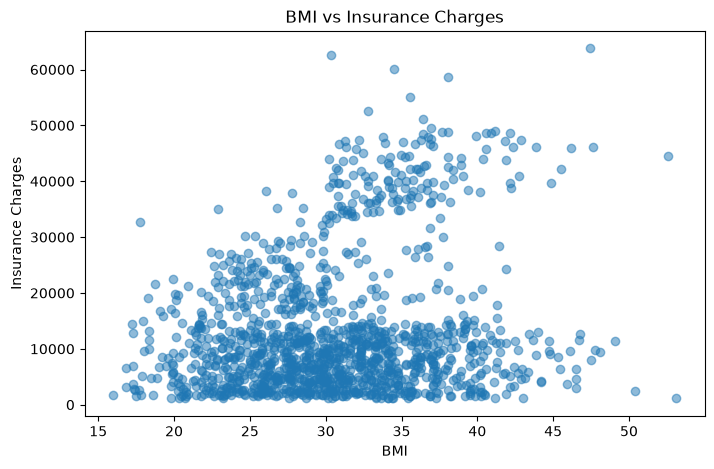

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df["bmi"], df["charges"], alpha=0.5)

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("BMI vs Insurance Charges")

plt.show()

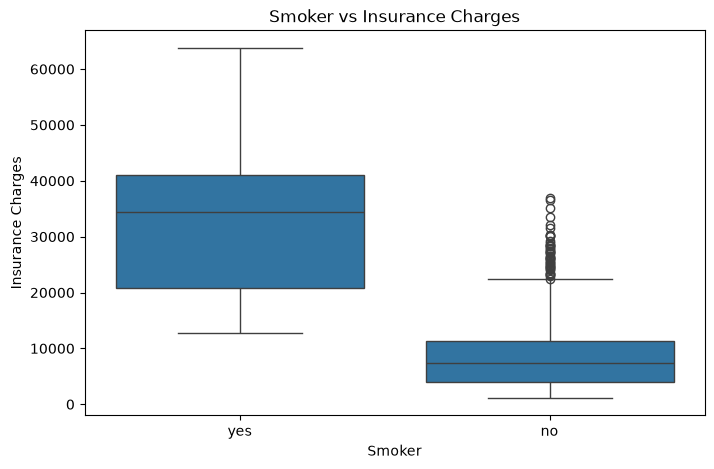

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(x="smoker", y="charges", data=df)

plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")
plt.title("Smoker vs Insurance Charges")

plt.show()

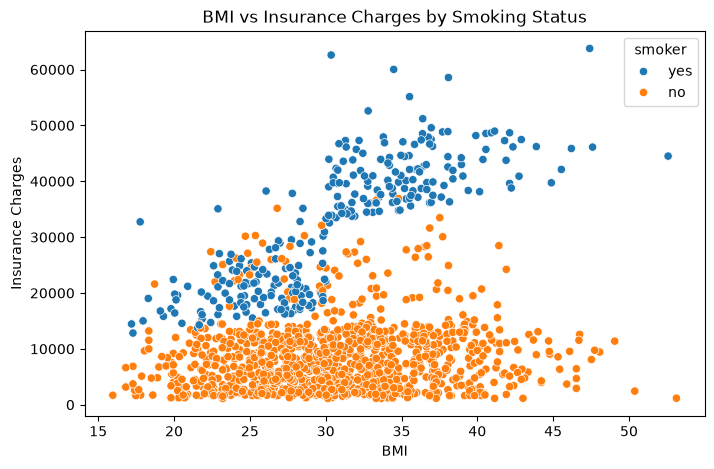

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("BMI vs Insurance Charges by Smoking Status")

plt.show()

Correlation Analysis

In [17]:
correlation = df.corr(numeric_only=True)

correlation

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


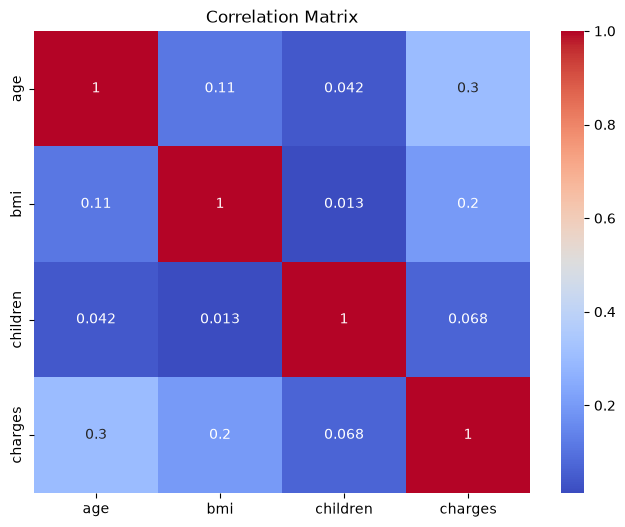

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

Data Preprocessing

In [19]:
# Create feature matrix
X = df[
    [
        "age",
        "sex",
        "bmi",
        "children",
        "smoker",
        "region"
    ]
].copy()

In [20]:
# Encode sex
X["sex"] = X["sex"].replace({
    "male": 0,
    "female": 1
})

# Encode smoker
X["smoker"] = X["smoker"].replace({
    "no": 0,
    "yes": 1
})

In [21]:
# One-hot encode region
region_encoded = pd.get_dummies(
    X["region"],
    dtype=int
)

In [22]:
# Remove original region column
X = X.drop("region", axis=1)

In [23]:
# Add encoded region columns
X = pd.concat(
    [X, region_encoded],
    axis=1
)

In [24]:
# Create BMI × Smoker interaction
X["bmi_smoker"] = X["bmi"] * X["smoker"]

# Target variable
y = df["charges"]

In [25]:
X.head()

,age,sex,bmi,children,smoker,northeast,northwest,southeast,southwest,bmi_smoker
0,19,1,27.900,0,1,0,0,0,1,27.9
1,18,0,33.770,1,0,0,0,1,0,0.0
2,28,0,33.000,3,0,0,0,1,0,0.0
3,33,0,22.705,0,0,0,1,0,0,0.0
4,32,0,28.880,0,0,0,1,0,0,0.0


In [26]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'northeast', 'northwest',
       'southeast', 'southwest', 'bmi_smoker'],
      dtype='str')

In [27]:
X.dtypes

age             int64
sex            object
bmi           float64
children        int64
smoker         object
northeast       int64
northwest       int64
southeast       int64
southwest       int64
bmi_smoker     object
dtype: object

Train/Test Split

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

Baseline Linear Regression

In [29]:
X_baseline = X.drop("bmi_smoker", axis=1)

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_baseline,
    y,
    test_size=0.20,
    random_state=42
)

In [30]:
baseline_model = LinearRegression()

baseline_model.fit(
    X_train_base,
    y_train_base
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 256.98, 18.59, 337.09,..., 88.91,-198.28,-350.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['age','sex','bmi',...,'northwest','southeast','southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.241e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [31]:
y_pred_baseline = baseline_model.predict(X_test_base)

In [32]:
baseline_mae = mean_absolute_error(
    y_test_base,
    y_pred_baseline
)

baseline_r2 = r2_score(
    y_test_base,
    y_pred_baseline
)

print(f"Baseline MAE: ${baseline_mae:,.2f}")
print(f"Baseline R²: {baseline_r2:.4f}")

Baseline MAE: $4,181.19
Baseline R²: 0.7836


Final Linear Regression Model

In [33]:
final_model = LinearRegression()

final_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 263.39, 525.23, 20.25,...,-259.4 ,-525.35,1470.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'southeast','southwest','bmi_smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3275
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [34]:
y_pred_final = final_model.predict(X_test)

Final Model Evaluation

In [35]:
final_mae = mean_absolute_error(
    y_test,
    y_pred_final
)

final_rmse = mean_squared_error(
    y_test,
    y_pred_final
) ** 0.5

final_r2 = r2_score(
    y_test,
    y_pred_final
)

print(f"MAE: ${final_mae:,.2f}")
print(f"RMSE: ${final_rmse:,.2f}")
print(f"R²: {final_r2:.4f}")

MAE: $2,756.90
RMSE: $4,573.81
R²: 0.8653


Model Comparison

In [36]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Baseline": [
        baseline_mae,
        np.nan,
        baseline_r2
    ],
    "Final Model": [
        final_mae,
        final_rmse,
        final_r2
    ]
})

comparison

,Metric,Baseline,Final Model
0,MAE,4181.194474,2756.898660
1,RMSE,NaN,4573.807686
2,R²,0.783593,0.865250


Actual vs Predicted

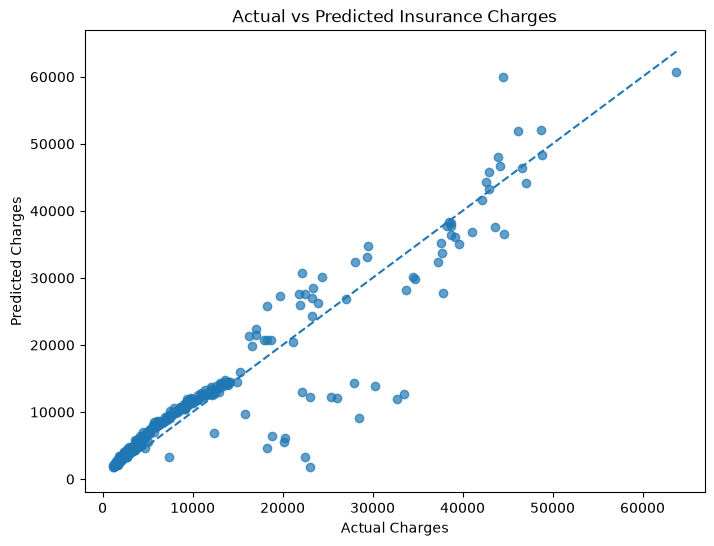

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

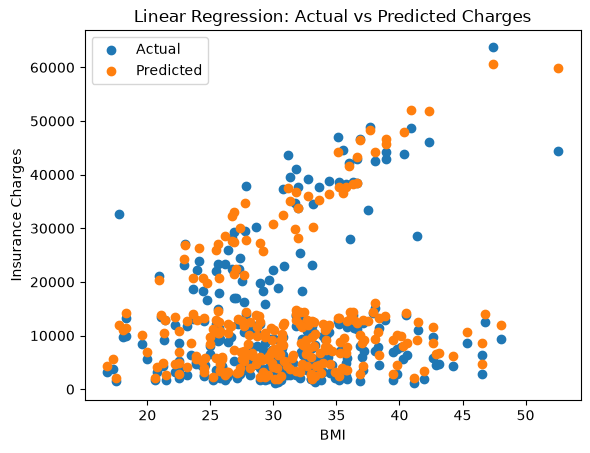

In [38]:
import matplotlib.pyplot as plt

plt.scatter(X_test["bmi"], y_test, label="Actual")
plt.scatter(X_test["bmi"], y_pred_final, label="Predicted")

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("Linear Regression: Actual vs Predicted Charges")
plt.legend()
plt.show()

Residual Analysis

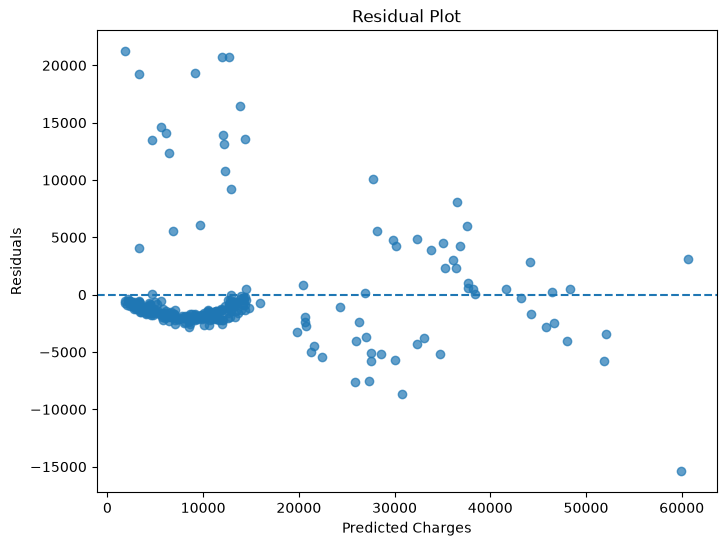

In [39]:
residuals = y_test - y_pred_final

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_final,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

BMI Regression Visualization

In [40]:
bmi_range = np.linspace(
    X_test["bmi"].min(),
    X_test["bmi"].max(),
    100
)

line_data = pd.DataFrame({
    "age": X_test["age"].mean(),
    "sex": X_test["sex"].mean(),
    "bmi": bmi_range,
    "children": X_test["children"].mean(),
    "smoker": X_test["smoker"].mean(),
    "northeast": X_test["northeast"].mean(),
    "northwest": X_test["northwest"].mean(),
    "southeast": X_test["southeast"].mean(),
    "southwest": X_test["southwest"].mean()
})

In [41]:
line_data["bmi_smoker"] = (
    line_data["bmi"] *
    line_data["smoker"]
)

line_predictions = final_model.predict(line_data)

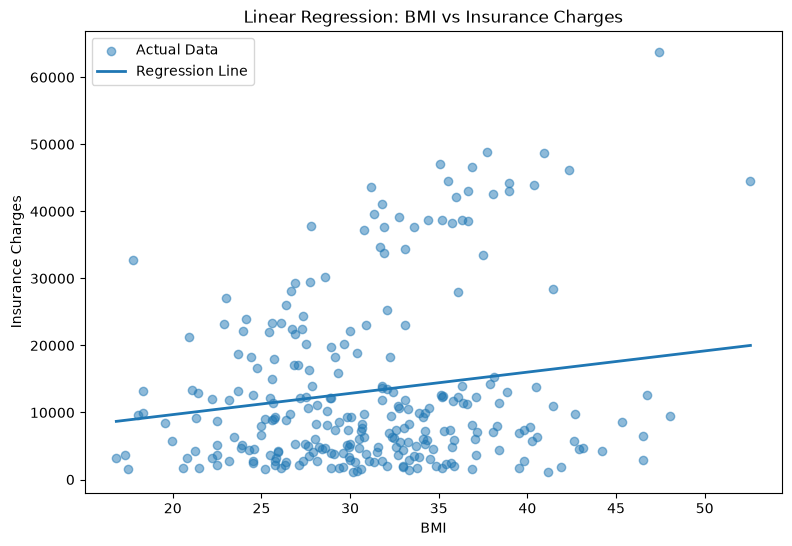

In [42]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test["bmi"],
    y_test,
    alpha=0.5,
    label="Actual Data"
)

plt.plot(
    bmi_range,
    line_predictions,
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("Linear Regression: BMI vs Insurance Charges")
plt.legend()

plt.show()

Test with a New Patient

In [43]:
new_patient = pd.DataFrame([{
    "age": 35,
    "sex": 1,
    "bmi": 28.5,
    "children": 1,
    "smoker": 1,
    "northeast": 0,
    "northwest": 0,
    "southeast": 1,
    "southwest": 0,
    "bmi_smoker": 28.5
}])

new_patient

,age,sex,bmi,children,smoker,northeast,northwest,southeast,southwest,bmi_smoker
0,35,1,28.5,1,1,0,0,1,0,28.5


In [44]:
prediction = final_model.predict(new_patient)

print(
    f"Predicted Insurance Charge: ${prediction[0]:,.2f}"
)

Predicted Insurance Charge: $27,963.00


## Conclusion

A Linear Regression model was developed to predict annual medical insurance charges.

The baseline model achieved:

- MAE: approximately $4,181
- R²: approximately 0.784

Feature engineering was then performed by introducing the `bmi_smoker` interaction feature.

The final model achieved:

- MAE: $2,756.90
- RMSE: $4,573.81
- R²: 0.8653

The feature engineering reduced the MAE by approximately 34.06% compared with the baseline model.

The final model achieved the project's R² target of 0.75–0.80, although the target MAE of below $1,500 was not achieved.

The model was also tested on a new patient and predicted an annual insurance charge of approximately $27,963.

Overall, the project demonstrates how Linear Regression combined with appropriate preprocessing, exploratory data analysis, and feature engineering can be used to estimate medical insurance costs.